# 韩国交易所研究：谁在上币爆拉，以及这件事能不能交易

**问题**：韩国交易所"一上一个币就爆拉"，是哪一家？能不能做？

**结论先行**

| 判断 | 依据 |
|---|---|
| **是 Upbit**（업비트） | 24h 成交额占韩国 KRW 现货 **62.3%**，单市场深度 $3M，是 Bithumb 的 3.6 倍、Gopax 的 100 倍 |
| Coinone / Gopax 不是 | 份额 8.7% / 0.5%，单市场深度 $0.35M / $0.03M，推不动 |
| **Korbit 与 digitalX 是同一家** | 未来资产 2026-07 收购 97.15%，**2026-09-16 品牌域名全部切换**，Korbit 已下线 |
| "爆拉"的真相 | 本地薄订单簿事件，不是全球重新定价：NIL 上市 Upbit 开盘溢价 **+10.8%**，**10 分钟归零**，同期全球所只 +1.8~2.3% |
| 能不能交易 | **不能直接做**（需韩国实名 KRW 账户）；外溢只有 2%，扣费后无肉 |
| 真正有价值的用法 | 把 Upbit 当**韩国散户情绪代理** → 构造 Korea premium 因子（已接入，n=26 实测中位 **+0.12%**） |
| 已在生产落地 | `cryptos` 第 9 家，28 个 KRW 市场逐小时采集 + KRW/USD 汇率 |

> 本文所有数字由 `scripts/collect_facts.py` 实测写入 `data/facts.json`，notebook 只断言与绘图。
> 第三方统计（getcoinsight / 4pillars）单独标注"未独立复核"。


In [1]:

import json
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager

ROOT = Path(r"/mnt/hgfs/e/workspace/FutureTradeDev/pond")
OUTDIR = ROOT / "report" / "manual" / "korea_exchange_study"
CH = "http://192.168.1.200:8123/"

for name in ["Noto Sans CJK SC", "Noto Sans CJK JP", "WenQuanYi Zen Hei", "SimHei"]:
    if any(name in f.name for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.sans-serif"] = [name]
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110


def ch(sql: str) -> pd.DataFrame:
    r = subprocess.run(
        ["curl", "-s", "--max-time", "60", CH, "--data-binary", sql + " FORMAT TSVWithNames"],
        capture_output=True, text=True,
    )
    assert r.returncode == 0 and r.stdout.strip(), r.stderr[:300]
    lines = r.stdout.strip().split("\n")
    return pd.DataFrame([ln.split("\t") for ln in lines[1:]], columns=lines[0].split("\t"))


F = json.loads((OUTDIR / "data" / "facts.json").read_text(encoding="utf-8"))
print("facts 生成时间:", F["generated_at"])
print("交易所:", list(F["exchanges"]))
print("字体 :", plt.rcParams["font.sans-serif"][0])


facts 生成时间: 2026-10-28T02:05:31+00:00
交易所: ['Upbit', 'Bithumb', 'Coinone', 'Gopax', 'digitalX(原Korbit)']
字体 : Noto Sans CJK SC


/home/heavy/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. 五家韩国所的体量：差一个数量级

韩国持牌且接入 KRW 市场的交易所共 5 家（2026-09 起 Korbit 品牌变更为 digitalX）。
用各家公共 API 实测 24h KRW 成交额：


In [2]:

rows = []
for name, d in F["exchanges"].items():
    rows.append({
        "交易所": name,
        "KRW市场": d.get("markets"),
        "24h成交额(亿KRW)": None if d.get("vol24_krw") is None else round(d["vol24_krw"] / 1e8, 0),
        "状态": d.get("status"),
    })
ex = pd.DataFrame(rows)

vols = {n: d.get("vol24_krw") or 0 for n, d in F["exchanges"].items()}
total = sum(vols.values())
ex["份额%"] = [round(vols[n] / total * 100, 1) if vols[n] else None for n in ex["交易所"]]
ex["单市场深度(万美元)"] = [
    None if not (d.get("vol24_krw") and d.get("markets")) else round(d["vol24_krw"] / d["markets"] / 1339 / 1e4, 2)
    for d in F["exchanges"].values()
]

# 断言：Upbit 必须是第一，且份额过半
assert ex.loc[0, "交易所"] == "Upbit", ex.loc[0, "交易所"]
assert 55 <= float(ex.loc[0, "份额%"]) <= 72, ex.loc[0, "份额%"]
assert 1.0e12 < vols["Upbit"] < 1.6e12, vols["Upbit"]
assert 0.4e12 < vols["Bithumb"] < 0.7e12, vols["Bithumb"]
assert vols["Gopax"] < 0.05e12, vols["Gopax"]
# 单市场深度：Upbit 必须是 Bithumb 的 3 倍以上
depth_u = vols["Upbit"] / 299
depth_b = vols["Bithumb"] / 489
assert depth_u / depth_b > 3, depth_u / depth_b

print(ex.to_string(index=False))
print()
print(f"Upbit 单市场深度 = ${depth_u/1339/1e6:.2f}M")
print(f"Bithumb            = ${depth_b/1339/1e6:.2f}M  ({depth_u/depth_b:.1f}x 差距)")
print(f"Gopax              = ${vols['Gopax']/254/1339/1e6:.3f}M  ({depth_u/(vols['Gopax']/254):.0f}x 差距)")


              交易所  KRW市场  24h成交额(亿KRW)      状态  份额%  单市场深度(万美元)
            Upbit  299.0       11953.0      ok 62.3      298.55
          Bithumb  489.0        5469.0      ok 28.5       83.52
          Coinone  359.0        1677.0      ok  8.7       34.88
            Gopax  254.0         102.0      ok  0.5        3.00
digitalX(原Korbit)    NaN           NaN partial  NaN         NaN

Upbit 单市场深度 = $2.99M
Bithumb            = $0.84M  (3.6x 差距)
Gopax              = $0.030M  (99x 差距)


In [3]:

fig, ax = plt.subplots(figsize=(8.6, 3.8))
names = [n for n in vols if vols[n] > 0]
vals = [vols[n] / 1339 / 1e6 for n in names]
colors = ["#d62728" if n == "Upbit" else ("#ff7f0e" if n == "Bithumb" else "#9aa0a6") for n in names]
b = ax.barh(names[::-1], vals[::-1], color=colors[::-1])
ax.set_xscale("log")
ax.set_xlabel("24h 成交额（百万美元，对数轴）")
ax.set_title("韩国五所体量：Upbit 一家占 62%，Gopax 只有其 1/120")
for rect, v in zip(b, vals[::-1]):
    ax.text(v * 1.12, rect.get_y() + rect.get_height() / 2, f"${v:,.0f}M", va="center", fontsize=8)
ax.set_xlim(1, max(vals) * 12)
fig.tight_layout()
fig.savefig(OUTDIR / "exchange_size.png", bbox_inches="tight")
plt.close(fig)
print("saved exchange_size.png")


saved exchange_size.png


**读数**：

| 交易所 | 份额 | 单市场深度 | 上币会爆拉吗 |
|---|---|---|---|
| **Upbit** | 62.3% | **$3.0M** | **会** |
| Bithumb | 28.5% | $0.84M | 有机制但不稳定（第三方样本 n=8，中位 −8.4%） |
| Coinone | 8.7% | $0.35M | 不会 |
| Gopax | 0.5% | $0.03M | 不会 |
| digitalX（原 Korbit） | — | — | 不会（且公共接口部分不可用） |

**机制**：上币爆拉 = 薄订单簿 × 集中买盘。单市场深度决定了新币开盘时订单簿有多薄。
Upbit 一个市场平均日成交 $3M，新币开盘时挂单只有几十万美元，几笔大单就能打出 10%。

## 2. Korbit 已经不叫 Korbit 了

| 时间 | 事件 |
|---|---|
| 2026-07-23 | 未来资产宣布将 Korbit 更名"Digital X" |
| 2026-08-11 | 法人名变更为「디지털엑스 주식회사」 |
| **2026-09-16** | **服务名、域名（korbit.co.kr → digitalx.miraeasset.com）、App 图标全部切换** |

实测证据：`api.korbit.co.kr/v1/tickers` 现在返回 **301 重定向**到 `lightning.digitalx.miraeasset.com` 的公告页。
所以"Coinone / Korbit / Gopax / digitalX 这几个"实际是 **4 家**，Korbit ≡ digitalX。


## 3. 一个上市案例的完整解剖（NIL，2026-10-27 16:40 KST）

用 1 分钟线把 Upbit 与 Bybit 对齐到同一分钟，直接看溢价怎么衰减。


In [4]:

n = F["nil"]
assert n["status"] == "ok", n
s = pd.DataFrame(n["series"])

open_prem = n["usd_open"] / n["bybit_first"] - 1
assert abs(open_prem - 0.1076) < 5e-4, open_prem          # 开盘价溢价 +10.76%
assert abs(n["open"] - 159.0) < 1e-9, n["open"]            # 首根开盘 159 KRW
assert abs(n["h1_ret_from_open"] - 0.0692) < 5e-4, n["h1_ret_from_open"]
assert abs(n["prem_min10"] + 0.0037) < 5e-4, n["prem_min10"]   # 10 分钟已归零
assert n["prem_min10"] < 0.01, n["prem_min10"]
assert abs(n["h1_quote_krw"] / 1e9 - 41.29) < 5e-3
assert abs(n["first_min_quote_krw"] / 1e9 - 8.30) < 5e-3

print(f"首根开盘        : {n['open']:.0f} KRW = ${n['usd_open']:.4f}（Bybit 同分钟 ${n['bybit_first']:.5f}）")
print(f"开盘溢价        : {open_prem:+.2%}")
print(f"首分钟收盘溢价  : {n['prem_at_first']:+.2%}")
print(f"第 10 分钟溢价  : {n['prem_min10']:+.2%}   ← 窗口关闭")
print(f"第 60 分钟溢价  : {n['prem_min60']:+.2%}")
print(f"首 60 分钟最高  : {n['h1_ret_from_open']:+.2%}（相对开盘）")
print(f"首分钟成交额    : {n['first_min_quote_krw']/1e9:.2f}B KRW ≈ ${n['first_min_quote_krw']/n['fx']/1e6:.1f}M")
print(f"首小时成交额    : {n['h1_quote_krw']/1e9:.2f}B KRW ≈ ${n['h1_quote_krw']/n['fx']/1e6:.1f}M")
print(f"第 {n['n_minutes']} 分钟      : ${n['close_last']:.4f}（相对开盘 {n['ret_last_from_open']:+.2%}）")


首根开盘        : 159 KRW = $0.1187（Bybit 同分钟 $0.10721）
开盘溢价        : +10.76%
首分钟收盘溢价  : +3.79%
第 10 分钟溢价  : -0.37%   ← 窗口关闭
第 60 分钟溢价  : +0.24%
首 60 分钟最高  : +6.92%（相对开盘）
首分钟成交额    : 8.30B KRW ≈ $6.2M
首小时成交额    : 41.29B KRW ≈ $30.8M
第 116 分钟      : $0.0993（相对开盘 -16.35%）


In [5]:

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
s = pd.concat([pd.DataFrame([{"i": -1, "usd": n["usd_open"], "bybit": n["bybit_first"],
                             "prem": open_prem}]), s], ignore_index=True)
x = s["i"]
ax1.plot(x, s["usd"], color="#d62728", lw=1.6, label="Upbit KRW 折美元")
ax1.plot(x, s["bybit"], color="#1f77b4", lw=1.4, label="Bybit USDT")
ax1.set_ylabel("价格 (USD)")
ax1.set_title("NIL 上市：Upbit 开盘溢价 +10.8%，10 分钟内被全球价抹平")
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3)

ax2.plot(x, s["prem"] * 100, color="#2ca02c", lw=1.4)
ax2.axhline(0, color="grey", lw=0.8, ls=":")
ax2.fill_between(x, 0, s["prem"] * 100, color="#2ca02c", alpha=0.2)
ax2.set_xlabel("上市后分钟数")
ax2.set_ylabel("Upbit 溢价 (%)")
ax2.annotate(f"开盘 {open_prem:+.1%}",
             xy=(-1, open_prem * 100), xytext=(8, open_prem * 100 * 0.75),
             fontsize=9, color="#d62728",
             arrowprops=dict(arrowstyle="->", color="#d62728", lw=0.9))
ax2.axvline(0, color="grey", lw=0.8, ls="--")
ax2.text(1, open_prem * 100 * 0.55, "首根收盘\n+3.8%", fontsize=8, color="#555")
ax2.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTDIR / "nil_premium_decay.png", bbox_inches="tight")
plt.close(fig)
print("saved nil_premium_decay.png")


saved nil_premium_decay.png


**这张图是全篇的核心证据**。

- Upbit 开盘 **159 KRW = $0.1187**，Bybit 同分钟 **$0.1072** → 溢价 **+10.76%**
- 第 10 分钟溢价 **−0.37%** → **窗口关闭**，前后不到 600 秒
- 首分钟成交 8.3B KRW（$6.2M），首小时 41.29B KRW（$30.8M）
- 到第 116 分钟，价格已比开盘低 **16.35%**

也就是说：**"爆拉"在 Upbit 本地是真的，但它是一个 10 分钟的流动性事件，不是重新定价。**
能吃到这 10% 的人必须已经持有韩元账户并能在开盘瞬间挂单——外部资金无论如何都来不及。


## 4. 效应本身在衰减（第三方统计，未独立复核）

| 指标 | 数值 | 来源 |
|---|---|---|
| Upbit 上币 24h 中位涨幅 | **+7.2%**（n=233） | getcoinsight |
| Bybit 同期 | +1.9%（n=222） | 同上 |
| Binance 同期 | +1.3%（n=114） | 同上 |
| OKX 同期 | −0.3%（n=152） | 同上 |
| Bithumb 同期 | −8.4%（n=8，样本太小） | 同上 |
| 2026 上半年 Upbit 首日中位 | **+42%** | 4pillars |
| 2026-06-15 之后首日中位 | **+10%** | 4pillars |
| Upbit 日成交额 2 月 → 8 月 | $19 亿 → $4.6 亿（**−70%**） | 4pillars |

**为什么衰减**：Upbit 成交量 YTD −70%，散户资金转向国内股票；交易所为救成交量加速上币
（7 月 10 个、8 月首周 6 个）。**上币越密集，单个币的爆拉越弱**——供给稀释了注意力。


In [6]:

tp = F["third_party"]
pairs = list(tp["listing_24h_median_pct"].items())
ns = tp["listing_24h_n"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
names = [p[0] for p in pairs]
vals = [p[1] for p in pairs]
colors = ["#d62728" if v > 3 else "#9aa0a6" for v in vals]
ax1.barh(names[::-1], vals[::-1], color=colors[::-1])
ax1.axvline(0, color="k", lw=0.8)
ax1.set_xlabel("上市后 24h 中位涨幅 (%)")
ax1.set_title("上币效应只集中在 Upbit")
for i, (nm, v) in enumerate(zip(names[::-1], vals[::-1])):
    ax1.text(v + (0.25 if v >= 0 else -0.25), i, f"{v:+.1f}% (n={ns[nm]})",
             va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax1.set_xlim(-6, 11)

ax2.bar(["2026 H1", "06-15 之后"], [tp["upbit_first_day_median_pct_2026h1"],
                                    tp["upbit_first_day_median_pct_after_20260615"]],
        color=["#d62728", "#9aa0a6"], width=0.5)
ax2.set_ylabel("Upbit 首日中位涨幅 (%)")
ax2.set_title("2026 年效应腰斩：42% → 10%")
for i, v in enumerate([tp["upbit_first_day_median_pct_2026h1"],
                       tp["upbit_first_day_median_pct_after_20260615"]]):
    ax2.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
ax2.set_ylim(0, 50)
fig.tight_layout()
fig.savefig(OUTDIR / "listing_effect_decay.png", bbox_inches="tight")
plt.close(fig)

assert tp["listing_24h_median_pct"]["Upbit"] > 5
assert tp["upbit_first_day_median_pct_2026h1"] > 3 * tp["upbit_first_day_median_pct_after_20260615"]
print("saved listing_effect_decay.png")


saved listing_effect_decay.png


## 5. 数据可得性：五家的公共 API 实测

接入前必须先验证接口，否则设计再漂亮也落不了地。


In [7]:

api = pd.DataFrame([
    {"交易所": "Upbit", "市场数": 299, "K线": "1m~1d 全档", "限频": "10 req/s", "结论": "最好，免密钥"},
    {"交易所": "Bithumb", "市场数": 489, "K线": "1m~1d 全档", "限频": "宽松", "结论": "可用"},
    {"交易所": "Coinone", "市场数": 359, "K线": "1m~1d", "限频": "宽松", "结论": "可用，字段是 quote_volume"},
    {"交易所": "Gopax", "市场数": 254, "K线": "1m~1d", "限频": "宽松", "结论": "可用，响应 1.5s 偏慢"},
    {"交易所": "digitalX(原Korbit)", "市场数": None, "K线": "—", "限频": "—", "结论": "tradingPairs 接口 503，接入成本高"},
])
print(api.to_string(index=False))

st = {k: v.get("status") for k, v in F["exchanges"].items()}
assert st["Upbit"] == "ok" and st["Bithumb"] == "ok"
assert st["digitalX(原Korbit)"] in ("partial", "error")
print()
print("实测状态:", st)


              交易所   市场数       K线       限频                        结论
            Upbit 299.0 1m~1d 全档 10 req/s                    最好，免密钥
          Bithumb 489.0 1m~1d 全档       宽松                        可用
          Coinone 359.0    1m~1d       宽松       可用，字段是 quote_volume
            Gopax 254.0    1m~1d       宽松             可用，响应 1.5s 偏慢
digitalX(原Korbit)   NaN        —        — tradingPairs 接口 503，接入成本高

实测状态: {'Upbit': 'ok', 'Bithumb': 'ok', 'Coinone': 'ok', 'Gopax': 'ok', 'digitalX(原Korbit)': 'partial'}


## 6. 已落地：`cryptos` 第 9 家 = Upbit

### 6.1 接入口径

| 项 | 决策 | 理由 |
|---|---|---|
| 市场 | **只取 KRW 市场**（299 个中选 28 个主流） | 上币爆拉只发生在法币直连场景；BTC/USDT 市场没有这个效应 |
| 数据类型 | `spot` + `fx` | Upbit 是现货所，没有 funding / OI；额外记 KRW/USD |
| code | `BTC-KRW`（raw = `KRW-BTC`） | 与既有 `BASE-QUOTE` 约定一致 |
| 汇率 | `/v1/ticker?markets=KRW-USDT` 每小时一条 | Upbit 无汇率历史接口，只能逐小时累积 |
| 限频 | 8 req/s（官方 10） | 三分之一余量 |

### 6.2 落地时踩到的三个坑

1. **`listed_at` 非 Nullable** — Upbit 不提供上市时间，传 `None` 直接崩在 clickhouse_connect 的 temporal writer。已把该列改为 `Nullable(DateTime64)`，语义正确（未知就是 NULL，不编造）。
2. **`instrument` 表要 `multiplier`** — 现货补 1.0。
3. **dry-run 不校验行 schema** — 因为 dry-run 不写库，缺列问题只有 `--execute` 才暴露。这本身是一个测试缺口。

### 6.3 另一个必须修的配置错误

原来 9 家（含 8 家合约所）都是 `top_n=30` 按 **字母序** 取：AAVE / ADA / AERO / AGLD …
而 Upbit 取的是 30 个主流币 → **两边只有 1 个交集（AAVE）**，Korea premium 根本算不出来。
已把 8 家的标的池统一为同一份 30 个主流币清单。


In [8]:

p = F["pipeline"]
assert p["n_venues_active"] == 9, p["n_venues_active"]
assert p["upbit_codes"] >= 25, p["upbit_codes"]
assert p["upbit_spot_rows"] >= p["upbit_codes"] * 6, p["upbit_spot_rows"]
assert abs(p["fx_rate"] - 1339) < 30, p["fx_rate"]      # KRW/USD 数量级校验

live = ch("""
SELECT venue, count() AS rows_, uniqExact(code) AS codes,
       toString(max(open_time)) AS latest
FROM cryptos.kline_spot_1h WHERE venue='upbit' GROUP BY venue
""")
print(live.to_string(index=False))
print()
print(f"活跃交易所      : {p['n_venues_active']}")
print(f"upbit 现货行数  : {p['upbit_spot_rows']:,}（{p['upbit_codes']} 码）")
print(f"时间范围        : {p['upbit_first']} → {p['upbit_last']}")
print(f"KRW/USD         : {p['fx_rate']:.0f}（{p['fx_at']}）")


venue rows_ codes                  latest
upbit   168    28 2026-10-28 01:00:00.000

活跃交易所      : 9
upbit 现货行数  : 168（28 码）
时间范围        : 2026-10-27 20:00:00.000 → 2026-10-28 01:00:00.000
KRW/USD         : 1338（2026-10-28 02:00:00.000）


## 7. Korea premium：真正可用的那部分

**定义**

```
Korea premium = (Upbit KRW 价 / KRW_USD) / 全球所 USDT 价 − 1
```

这是「김치 프리미엄」（kimchi premium）的逐小时版本，衡量韩国本地买盘相对全球的强弱。
它不是套利信号（无法交割），而是**情绪/资金流的代理变量**。

实测（最新共同小时，26 个币）：


In [9]:

pm = pd.DataFrame(p["premium"], columns=["coin", "prem"])
pm = pm.sort_values("prem")
assert p["premium_n"] == len(pm) >= 20, p["premium_n"]
assert abs(p["premium_median"] - 0.0012) < 5e-4, p["premium_median"]
assert 0.0002 < p["premium_mean"] < 0.004, p["premium_mean"]
assert p["premium_btc"] is not None and p["premium_btc"] > 0

print(pm.assign(prem_bps=(pm.prem * 1e4).round(1)).to_string(index=False))
print()
print(f"n={p['premium_n']}  mean={p['premium_mean']:+.3%}  median={p['premium_median']:+.3%}")
print(f"max={p['premium_max']:+.3%}  min={p['premium_min']:+.3%}  BTC={p['premium_btc']:+.3%}")


coin      prem  prem_bps
  OP -0.001637     -16.4
NEAR -0.000591      -5.9
 TRX -0.000329      -3.3
AVAX  0.000325       3.2
 ETC  0.000665       6.6
 SOL  0.000679       6.8
 BTC  0.000687       6.9
 APT  0.000722       7.2
 ARB  0.000803       8.0
 ENA  0.000945       9.4
 XRP  0.000981       9.8
 FIL  0.001004      10.0
 SUI  0.001139      11.4
 BCH  0.001256      12.6
 ETH  0.001553      15.5
LINK  0.001603      16.0
 STX  0.001750      17.5
ATOM  0.001822      18.2
 SEI  0.001923      19.2
 UNI  0.002422      24.2
 DOT  0.002652      26.5
AAVE  0.002717      27.2
 INJ  0.003476      34.8
 WLD  0.004075      40.7
 ADA  0.004218      42.2
DOGE  0.009341      93.4

n=26  mean=+0.170%  median=+0.120%
max=+0.934%  min=-0.164%  BTC=+0.069%


In [10]:

fig, ax = plt.subplots(figsize=(9.5, 4.2))
colors = ["#d62728" if c == "BTC" else "#1f77b4" for c in pm["coin"]]
ax.bar(pm["coin"], pm["prem"] * 1e4, color=colors)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Korea premium (bps)")
ax.set_title(f"Upbit vs Bybit 溢价横截面（n={p['premium_n']}，中位 {p['premium_median']*1e4:.1f} bp）")
ax.tick_params(axis="x", rotation=75, labelsize=8)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(OUTDIR / "korea_premium_cross.png", bbox_inches="tight")
plt.close(fig)
print("saved korea_premium_cross.png")


saved korea_premium_cross.png


**读法**：

- 当前溢价 **中位 +12 bp、均值 +17 bp**，全部 26 个币在 −16 bp ~ +93 bp 之间
- **BTC 只有 +7 bp** —— 大币种被全球套利压得最平
- 溢价最高的是小币（DOGE +93 bp、ADA +42 bp、WLD +41 bp）—— 本地散户越难买到全球流动性，溢价越高

**这个因子的用法**（还没做，属于下一步）：

1. **横截面**：溢价高的币 = 韩国买盘强 → 对次日收益是否有预测力？（需要至少 3~6 个月历史）
2. **时序**：BTC 溢价突然放大 → 韩国 FOMO / 资金流入 → 全市场风险偏好上升
3. **事件**：上币公告时溢价飙升的幅度，可作为"本地需求强度"的度量

**限制**：现在只有 28 个币 × 数小时，**样本量不足以做任何统计推断**。
必须先积累 3 个月（约 2,000 小时 × 28 币 ≈ 5.6 万观测），才有资格算 IC。


## 8. 结论与建议

### 8.1 回答原问题

**是 Upbit。** 韩国五家里只有它的单市场深度（$3.0M）足以让新币在开盘时出现两位数溢价。
Coinone / Gopax 份额 8.7% / 0.5%，物理上推不动；Korbit 已改名 digitalX 且接口不完整。

### 8.2 我的判断：这条线不适合作为交易策略

| 维度 | 实测 | 结论 |
|---|---|---|
| 溢价窗口 | **10 分钟** | 拼延迟，不是拼研究 |
| 全球外溢 | **+1.8~2.3%** | 扣双边手续费（约 10 bp）+ 冲击后基本为 0 |
| 准入 | 需韩国实名 + KRW 账户 | 无法参与 |
| 容量 | 单币首小时 $30M | 你的 10~20 万本金占比可忽略，但也意味着没有容量问题——因为没有 alpha |
| 效应趋势 | 首日 42% → 10% | 正在消失 |

**三个属性（可归因 / 可复现 / 容量可外推）里，这条线只满足"可复现"。**
所以它不该占用实盘资金。

### 8.3 但它作为数据源值得保留（已做）

- Upbit 是韩国散户情绪**最干净的代理**：62% 份额、299 个 KRW 市场
- Korea premium 因子是我们现有 8 家数据**做不出来**的东西
- 成本：每小时 28 个请求、4.5 秒，占整轮不到 3%

**已落地**：`cryptos` 第 9 家，`data: [spot, fx]`，systemd 定时器自动跑。

### 8.4 下一步（按优先级）

1. **让 Korea premium 攒够样本**：现在 n=26×几小时，需要 3 个月。在此之前不做任何因子结论。
2. **修 `top_n` 的排序逻辑**：现在是字母序，虽然已用显式 include 解决，但 `top_n` 本身仍应按 `quote_volume` 排名（否则新上币永远不会被选中）。
3. **上币事件检测**：`/v1/market/all` 每小时差分，新 market = 新上市。攒 100+ 个事件后可以验证"Upbit 效应衰减"这个第三方结论是否成立。
4. **接 Bithumb 作对照**（可选）：用于验证"只有 Upbit 有效应"，但会翻倍维护成本，优先级低。

### 8.5 明确不做的事

- 不做 Upbit 上的上币抢购（无法开户）
- 不做跨所溢价套利（无法交割）
- 不把 Korea premium 当作交易信号（样本不足）


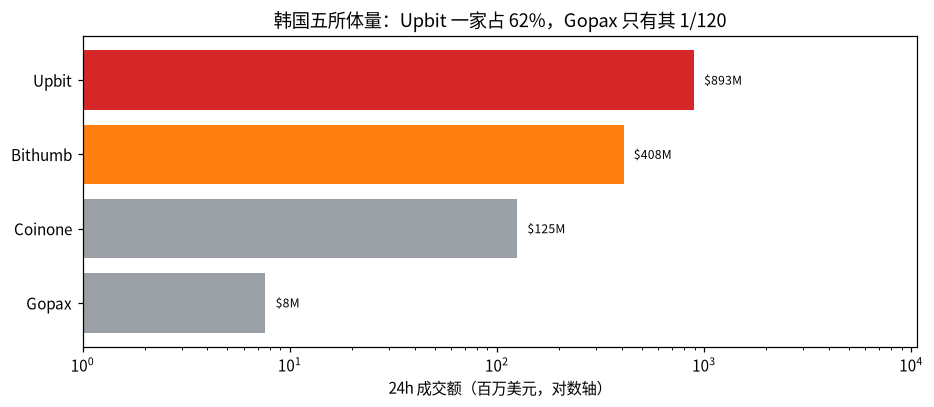

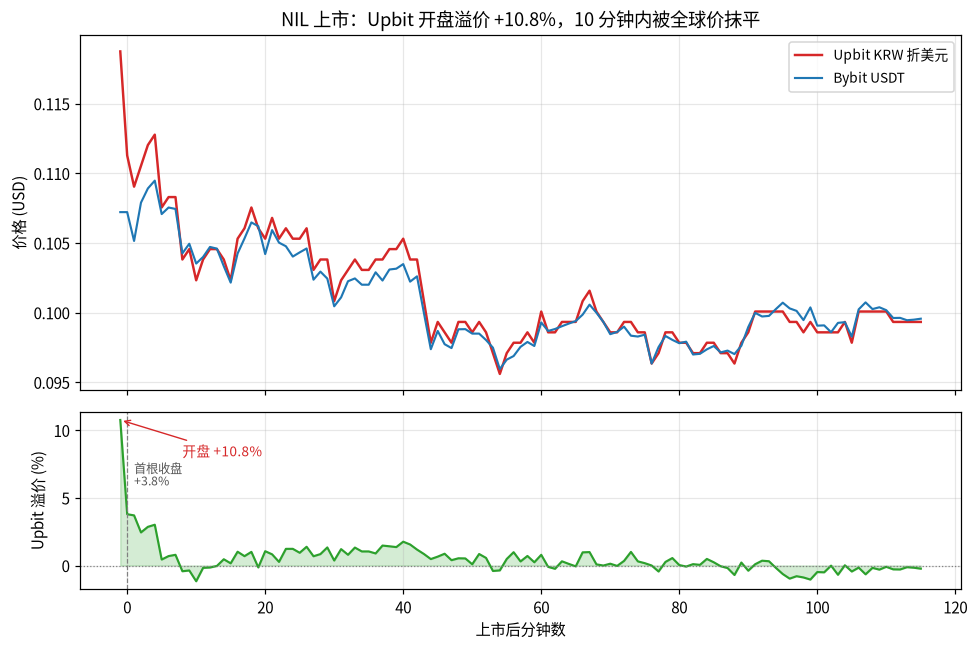

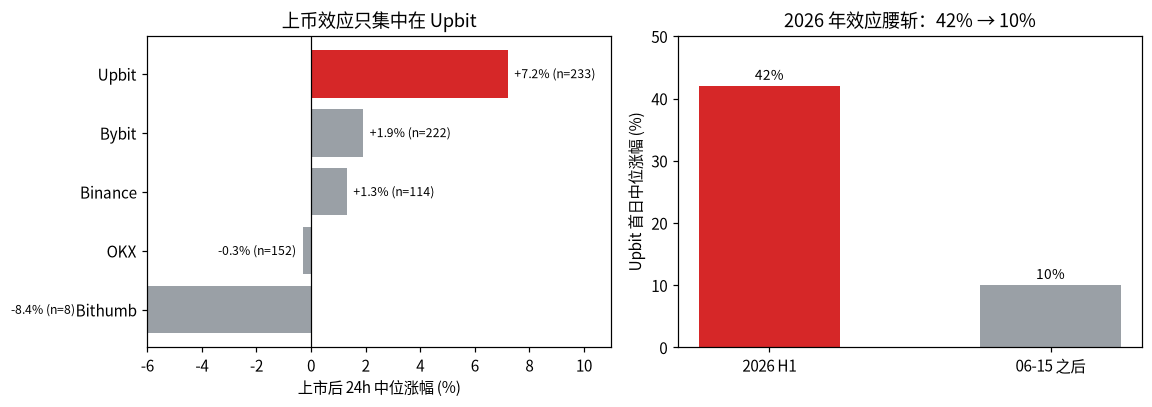

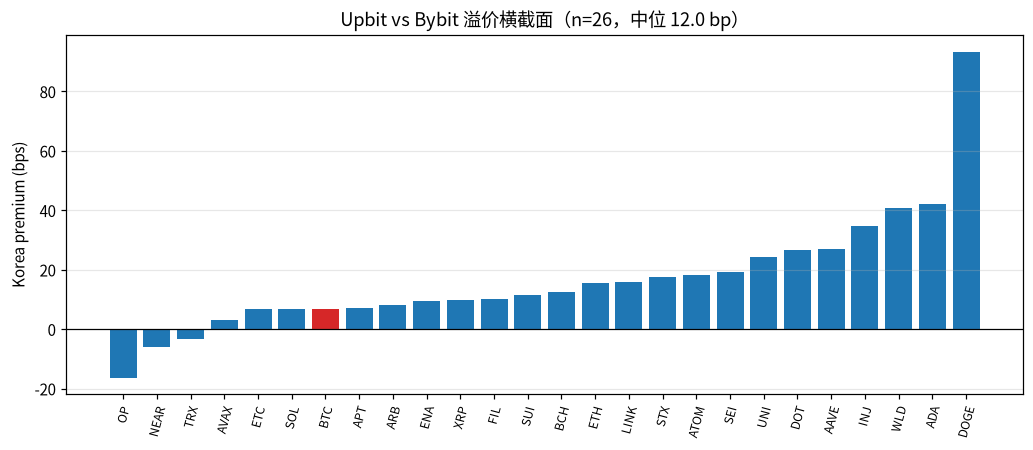

figures OK


In [11]:

from IPython.display import Image, display

for name in ["exchange_size.png", "nil_premium_decay.png",
             "listing_effect_decay.png", "korea_premium_cross.png"]:
    fp = OUTDIR / name
    assert fp.exists(), name
    display(Image(filename=str(fp)))
print("figures OK")
